# **Projeto Ciencia de Dados**

Fonte de dados kaggle: [Salary](https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression)

In [69]:
# importação das bibliotecas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Separador de milhar com vírgula e 2 casas decimais
pd.options.display.float_format = lambda x: f"{x:,.2f}"

# verificação do separador csv se é ";" ou ","
!head -n 5 'Salary_dataset.csv'

,YearsExperience,Salary
0,1.2000000000000002,39344.0
1,1.4000000000000001,46206.0
2,1.6,37732.0
3,2.1,43526.0


In [68]:

# Tabela
tb_salary = pd.read_csv('Salary_dataset.csv', encoding='latin1')

print("Tabela")
display(tb_salary.head())

# Tamanho dos dados
print("===============Tamanho dos dados===============")
display(tb_salary.shape)

# Foramatção das colunas
print("===============Formatação das colunas==========")
display(tb_salary.info())

# Verificação de dados duplicados
print("============Verificar Valores Duplicados=========")
display(tb_salario.duplicated().sum())

# Verificação de valores nulos
print("============ Verificação de valores faltantes====")
display(tb_salario.isnull().sum())


Tabela


,Unnamed: 0,YearsExperience,Salary
0,0,1.20,"39,344.00"
1,1,1.40,"46,206.00"
2,2,1.60,"37,732.00"
3,3,2.10,"43,526.00"
4,4,2.30,"39,892.00"


===============Tamanho dos dados===============


(30, 3)

===============Formatação das colunas==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


None

============Verificar Valores Duplicados=========


np.int64(0)

============ Verificação de valores faltantes====


,0
YearsExperience,0
Salary,0


Nota:


*   Dados formatados da maneira correta
*   Não há valores duplicados,nem valores ausentes

In [41]:
# Tabela atualizada
tb_salario = tb_salary[['YearsExperience', 'Salary']]

# Renomeando as colunas
tb_salario1 = tb_salario.rename(columns={'YearsExperience': 'ano_experiencia', 'Salary': 'salario'})

# Tabela
print("Tabela Atualizada")
display(tb_salario1.head())

# Descrição dos dados
print("==========Descrição================")
display(tb_salario1.describe())


Tabela Atualizada


,ano_experiencia,salario
0,1.20,"39,344.00"
1,1.40,"46,206.00"
2,1.60,"37,732.00"
3,2.10,"43,526.00"
4,2.30,"39,892.00"


==========Descrição================


,ano_experiencia,salario
count,30.00,30.00
mean,5.41,"76,004.00"
std,2.84,"27,414.43"
min,1.20,"37,732.00"
25%,3.30,"56,721.75"
50%,4.80,"65,238.00"
75%,7.80,"100,545.75"
max,10.60,"122,392.00"


NOTA:


*   A média de anos de experiencia é de 5 anos
*   O salario minimo é de 37.732,00,é o maior é de 122.392,00



Correlação


<Axes: >

===================Visualização==================


<Axes: xlabel='ano_experiencia', ylabel='salario'>

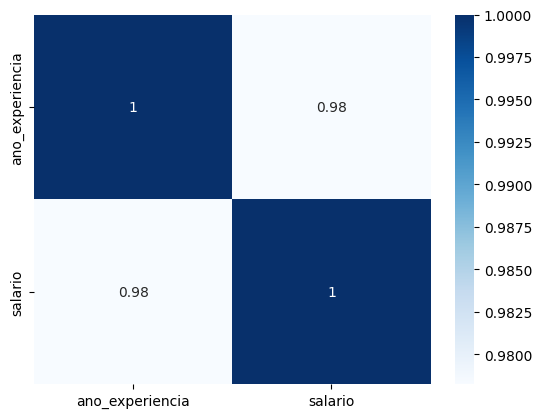

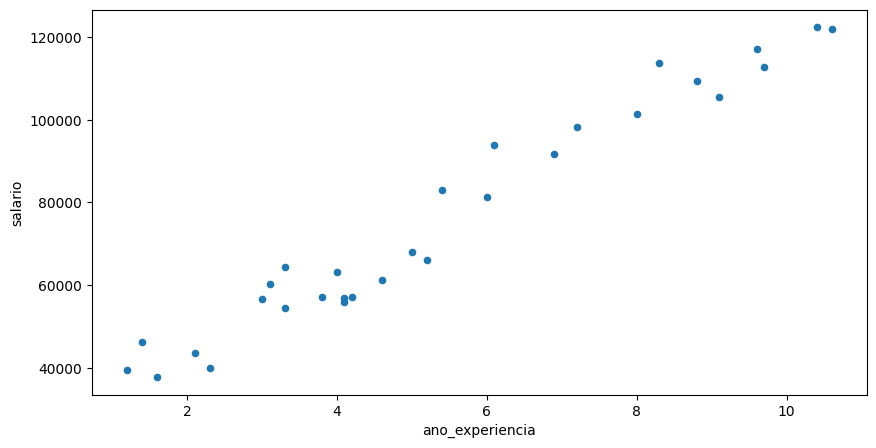

In [39]:
# Correlação entre ano de experiencia e salario
print("Correlação")
display(sns.heatmap(tb_salario1.corr(), annot=True, cmap='Blues'))

# Grafico correlção
print("===================Visualização==================")
display(tb_salario1.plot(kind='scatter', x='ano_experiencia', y='salario', figsize=(10,5)))


NOTA:


*   Existe uma correlação positiva forte de 0.98 de 1
*   Isso mostra quanto maior é a expericia maior é o salario



In [44]:
# Média de salario por salarios ranking dos 10 maiores
Rankin10_salarios = tb_salario1.groupby('ano_experiencia')['salario'].mean().nlargest(10)
Rankin10_salarios

,salario
ano_experiencia,
10.40,"122,392.00"
10.60,"121,873.00"
9.60,"116,970.00"
8.30,"113,813.00"
9.70,"112,636.00"
8.80,"109,432.00"
9.10,"105,583.00"
8.00,"101,303.00"
7.20,"98,274.00"


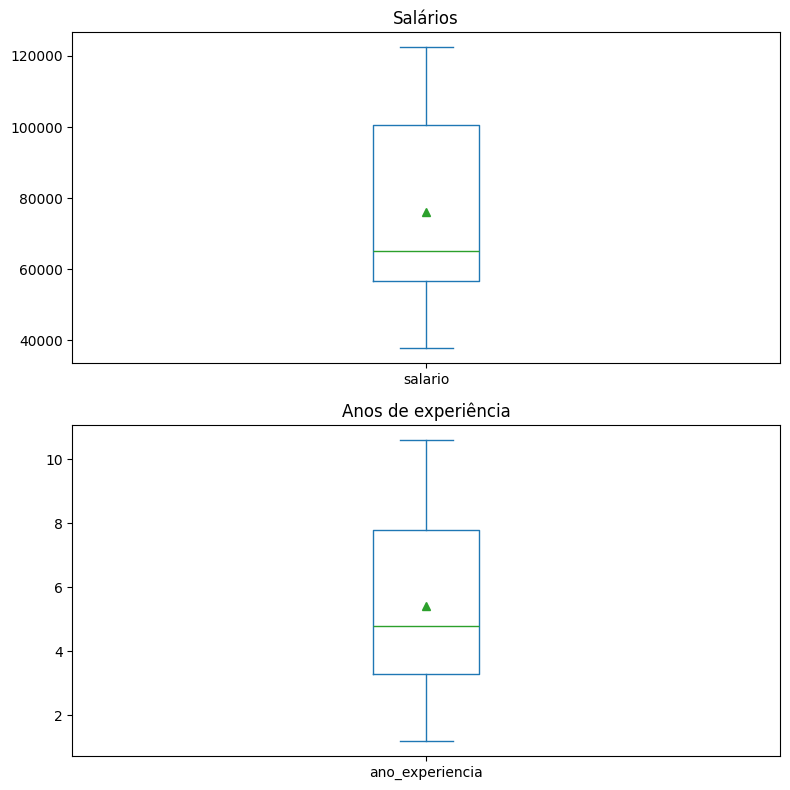

In [55]:
# Boxplot média e mediana
fig, axes = plt.subplots(2, 1, figsize=(8, 8))

# 1.ª salário
tb_salario1["salario"].plot(kind="box", ax=axes[0], showmeans=True)
axes[0].set_title("Salários")

# 2.ª anos de experiência
tb_salario1["ano_experiencia"].plot(kind="box", ax=axes[1], showmeans=True)
axes[1].set_title("Anos de experiência")

plt.tight_layout()
plt.show()

NOTA:


*   Os salarios fica entre 50 mil e 100mil
*   As experiencias está distribuidas entre 3,5 anos á 8 anos



In [58]:
# Salario médio a cada 5 anos

# Cria faixas de 5 em 5 anos (0, 5, 10, 15...)
faixa_5_anos = (tb_salario1["ano_experiencia"] // 5) * 5

# Calcula a média salarial por faixa e o % de aumento em relação à faixa anterior
resumo_5_anos = (
    tb_salario1.groupby(faixa_5_anos)["salario"]
    .mean()
    .to_frame(name="salario_medio")
)
resumo_5_anos

,salario_medio
ano_experiencia,
0.00,"52,916.13"
5.00,"95,547.15"
10.00,"122,132.50"


In [63]:
# Declaração das variaveis
x = tb_salario1[['ano_experiencia']]
y = tb_salario1['salario']

# Treinando o modelo
modelo = LinearRegression()
modelo.fit(x, y)

# Prevendo novos anos de experiencia e seus salarios
experiencia = pd.DataFrame({'ano_experiencia': [12, 15, 18, 20, 22, 25, 30]})
salario_previsto = modelo.predict(experiencia)

experiencia['salario_previsto'] = salario_previsto
experiencia

,ano_experiencia,salario_previsto
0,12,"138,247.75"
1,15,"166,597.64"
2,18,"194,947.53"
3,20,"213,847.45"
4,22,"232,747.38"
5,25,"261,097.26"
6,30,"308,347.07"


In [70]:
# Previsões nos mesmos dados onde já tens o salário real (y)
y_previsto_treino = modelo.predict(x)

mae = mean_absolute_error(y, y_previsto_treino)
rmse = np.sqrt(mean_squared_error(y, y_previsto_treino))
r2 = r2_score(y, y_previsto_treino)

print(f"Erro médio absoluto (MAE): {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

Erro médio absoluto (MAE): 4644.20
RMSE: 5592.04
R²: 0.9570


NOTA:


*   MAE: 4644.20 → o modelo erra, em média, 4.644,20 no salário (para mais ou para menos).
*   RMSE: 5592.04 → também é o tamanho do erro (na mesma moeda do salário), mas pesa mais quando há algum erro grande.
*   R²: 0.9570 → o modelo acerta/explica 95,7% de como o salário muda conforme os anos de experiência.

